# 8. Dashboard: implementación ejecutada

Este cuaderno es el **archivo fuente ejecutado del dashboard** del proyecto (riesgo de incumplimiento en Home Credit y el
modelo original ELAR-R). La aplicación web está escrita en Dash (`app.py`, `pages/`, `src/`) y publicada en
**https://dashriesgocrediticio.onrender.com**.

Aquí no se reescribe nada: el cuaderno importa la misma aplicación que corre en Render y **llama a sus propios callbacks**
(las funciones que Dash ejecuta cuando el usuario abre una pestaña, mueve un filtro o pulsa «Calcular riesgo»). Cada figura
de abajo es la misma que dibuja el dashboard, exportada como imagen para que quede visible en el cuaderno.

| Sección | Qué muestra |
|---|---|
| 1 | Entorno y carga de la aplicación |
| 2 | Arquitectura: páginas, callbacks y archivos que lee |
| 3 | Datos preparados fuera de línea y modelos serializados |
| 4 | Página **Contexto** (`/`) |
| 5 | Página **Exploración EDA** (`/eda`) |
| 6 | Página **Modelos & Predicción** (`/modelos`): resultados |
| 7 | **Simulador**: predicción en vivo, explicación local y casos de ELAR-R |
| 8 | Prueba de la aplicación web y validación de las cifras |

La descripción completa del diseño está en `08_dashboard.md`.

## 1. Entorno y carga de la aplicación

In [1]:
import os, sys, platform, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# El cuaderno funciona desde la raiz del repositorio o desde una subcarpeta (p. ej. JupyterRiesgoCrediticio/)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app.py").is_file())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("E3_SIN_GPU", "1")        # igual que en Render
os.environ.setdefault("OMP_NUM_THREADS", "1")

import app as aplicacion                         # la misma aplicacion que ejecuta gunicorn en Render
import dash, plotly, numpy as np, pandas as pd, sklearn, xgboost, joblib, scipy
from src import servicio as sv, theme as th

print(f"Raíz del repositorio: {RAIZ.name}")
print(f"Python {platform.python_version()} ({platform.system()})")
pd.DataFrame({"paquete": ["dash", "plotly", "numpy", "pandas", "scipy", "scikit-learn", "xgboost", "joblib"],
              "versión": [dash.__version__, plotly.__version__, np.__version__, pd.__version__, scipy.__version__,
                          sklearn.__version__, xgboost.__version__, joblib.__version__]}).set_index("paquete").T

Raíz del repositorio: Salirdelpaso-main
Python 3.12.7 (Windows)


paquete,dash,plotly,numpy,pandas,scipy,scikit-learn,xgboost,joblib
versión,4.1.0,5.24.1,2.2.6,2.3.3,1.15.3,1.7.2,3.0.5,1.5.2


Son las versiones fijadas en `requirements_dashboard.txt`, las mismas con que se serializaron los modelos y las que instala
Render (Python 3.12.7, archivo `.python-version`).

Funciones auxiliares: `mostrar` exporta una figura de Plotly a PNG y la muestra con su título y su nota (los mismos textos que
ve el usuario del dashboard); `texto` extrae el texto de un componente de Dash.

In [2]:
from IPython.display import Image, Markdown, display

TEMA = "claro"
PAGINAS = {p["path"]: sys.modules[p["module"]] for p in dash.page_registry.values()}
contexto, eda, modelos = PAGINAS["/"], PAGINAS["/eda"], PAGINAS["/modelos"]

def texto(c, sep="\n"):
    if c is None or isinstance(c, bool):
        return ""
    if isinstance(c, (str, int, float)):
        return str(c)
    if isinstance(c, (list, tuple)):
        return " ".join(t for t in (texto(x, sep) for x in c) if t.strip())
    t = texto(getattr(c, "children", None), sep)
    bloque = type(c).__name__ in {"H1", "H2", "H3", "H4", "P", "Li", "Div", "Section", "Alert", "Tr", "Header"}
    return f"{sep}{t}{sep}" if bloque and t.strip() else t

def limpio(s):
    return "\n".join(l.strip() for l in s.splitlines() if l.strip())

def mostrar(fig, titulo=None, nota=None, ancho=1000):
    if titulo:
        display(Markdown(f"**{texto(titulo).strip()}**"))
    alto = int(fig.layout.height or 420)
    display(Image(fig.to_image(format="png", width=ancho, height=alto, scale=1.4), width=ancho))
    if nota:
        display(Markdown(f"<small>{texto(nota).strip()}</small>"))

print("Páginas registradas:", {k: v.__name__ for k, v in PAGINAS.items()})

Páginas registradas: {'/': 'pages.01_contexto', '/eda': 'pages.02_eda', '/modelos': 'pages.03_modelos'}


## 2. Arquitectura

```text
datos/ (no está en el repositorio)          artifacts/*.joblib        entrega_persona3/*.csv
        │                                          │                          │
        └──────► scripts/preparar_dashboard.py ◄───┘                          │
                          │                                                   │
                          ▼                                                   │
                  dashboard_data/  (agregados, calibradores, casos)           │
                          │                                                   │
                          └──────────────► src/servicio.py ◄──────────────────┘
                                                  │
                    src/theme.py ─► src/plots.py ─┤─► pages/01_contexto.py   /
                    assets/style.css, scroll.js   ├─► pages/02_eda.py        /eda
                                                  └─► pages/03_modelos.py    /modelos
                                                              │
                                                           app.py  ──►  gunicorn app:server
```

In [3]:
paginas = pd.DataFrame([{"ruta": p["path"], "nombre": p["name"], "módulo": p["module"]}
                        for p in sorted(dash.page_registry.values(), key=lambda p: p["module"])])
aplicacion.server.test_client().get("/_dash-dependencies")   # Dash registra los callbacks de las paginas en la primera peticion
print(f"Callbacks registrados en la aplicación: {len(aplicacion.app.callback_map)}")
paginas

Callbacks registrados en la aplicación: 15


,ruta,nombre,módulo
0,/,Contexto,pages.01_contexto
1,/eda,Exploración EDA,pages.02_eda
2,/modelos,Modelos & Predicción,pages.03_modelos


In [4]:
def carpeta(nombre):
    archivos = [f for f in (RAIZ / nombre).rglob("*") if f.is_file()]
    return {"carpeta": nombre + "/", "archivos": len(archivos), "MB": round(sum(f.stat().st_size for f in archivos) / 2**20, 2),
            "ejemplos": ", ".join(sorted(f.name for f in archivos)[:5]) + (" …" if len(archivos) > 5 else "")}

print("Lo único que lee la aplicación (nunca los datos crudos de Kaggle):")
pd.DataFrame([carpeta(c) for c in ("dashboard_data", "entrega_persona3", "artifacts")]).set_index("carpeta")

Lo único que lee la aplicación (nunca los datos crudos de Kaggle):


,archivos,MB,ejemplos
carpeta,,,
dashboard_data/,21,1.54,"arbol.joblib, casos_elar.json, curvas.json, ed..."
entrega_persona3/,13,0.09,"README.md, calibracion.csv, conformal.csv, cur..."
artifacts/,11,74.26,"README.md, arbol.joblib, control_prueba.npz, e..."


## 3. Datos preparados fuera de línea y modelos serializados

`scripts/preparar_dashboard.py` y `scripts/preparar_dashboard_resultados.py` calcularon, con los datos reales del capítulo 01,
los agregados de `dashboard_data/`. Su resumen:

In [5]:
r = sv.resumen()
pd.Series({
    "Etapa B (con datos reales)": r["etapa_b"],
    "Fecha de preparación": r["fecha"],
    "Solicitudes de desarrollo": f"{r['n_desarrollo']:,}",
    "Solicitudes de prueba": f"{r['n_prueba']:,}",
    "Prevalencia de mora": f"{r['prevalencia']:.2%}",
    "Coste de un falso negativo (en falsos positivos)": r["coste_fn"],
    "Entradas de los modelos del E3": r["n_columnas_e3"],
    "Entradas de ELAR-R": r["n_columnas_elar"],
    "Pesos ω de ELAR-R (lineal / pares / profunda)": " / ".join(f"{v:.3f}" for v in r["pesos_elar"]["omega"].values()),
    "Friedman en Home Credit (10 modelos)": f"χ² = {r['friedman_home_credit']['chi2']:.1f}, p = {r['friedman_home_credit']['p']:.1e}",
}, name="valor").to_frame()

,valor
Etapa B (con datos reales),True
Fecha de preparación,2026-11-15 18:37
Solicitudes de desarrollo,"246,008"
Solicitudes de prueba,"61,503"
Prevalencia de mora,8.07%
Coste de un falso negativo (en falsos positivos),10
Entradas de los modelos del E3,483
Entradas de ELAR-R,565
Pesos ω de ELAR-R (lineal / pares / profunda),0.501 / 0.000 / 0.499
Friedman en Home Credit (10 modelos),"χ² = 414.5, p = 1.1e-83"


Modelos serializados en `artifacts/` (los ganadores del Entregable 3 y ELAR-R), según `artifacts/metadata.json`:

In [6]:
meta = sv.metadatos()
filas = []
for m, v in meta.items():
    if not isinstance(v, dict) or "auc_prueba_artefacto" not in v:
        continue
    f = RAIZ / "artifacts" / f"{m}.joblib"
    u = v.get("umbral_coste")
    u = round(float(u), 4) if isinstance(u, (int, float)) else (r["pesos_elar"]["umbral"] if m == "elar_r" else u)
    filas.append({"modelo": th.nombre_modelo(m), "AUC en la prueba": round(v["auc_prueba_artefacto"], 4),
                  "umbral de coste": u, "MB": round(f.stat().st_size / 2**20, 1),
                  "en vivo": "sí" if m in sv.VIVOS else "no"})
pd.DataFrame(filas).sort_values("AUC en la prueba", ascending=False).set_index("modelo")

,AUC en la prueba,umbral de coste,MB,en vivo
modelo,,,,
ELAR-R,0.7899,0.091229,16.2,no
XGBoost,0.7754,0.089400,1.3,sí
Regresión logística,0.7597,0.522100,0.0,sí
SVM,0.7595,0.029400,1.3,sí
Random forest,0.7544,0.384100,15.2,sí
Árbol de decisión,0.7017,0.091700,0.0,sí
KNN,0.6975,0.090400,39.6,no
Naive Bayes,0.6477,0.943900,0.0,sí


## 4. Página «Contexto» (`/`)

Las escenas de la página, en orden (encabezados del layout):

In [7]:
lay = contexto.layout() if callable(contexto.layout) else contexto.layout

def encabezados(c, out):
    if isinstance(c, (list, tuple)):
        for x in c: encabezados(x, out)
    elif hasattr(c, "children"):
        if type(c).__name__ in ("H1", "H2"):
            out.append(f"{type(c).__name__}: {limpio(texto(c.children, ' '))}")
        encabezados(c.children, out)
    return out

print("\n".join(encabezados(lay, [])))

H1: 307,511 solicitudes de crédito, y hay que decidir sobre cada una
H2: Qué se predice, con qué y para qué
H2: El problema en una ecuación
H2: De la solicitud a la decisión en 7 pasos
H2: XGBoost gana por 0.0039 de AUC. ELAR-R no lo supera.


La comparación científica que cierra la página: tabla de líderes con las mismas 528 entradas para los 10 modelos.

In [8]:
lideres = sv.tabla("tabla_lideres.csv")
cols = [c for c in ["modelo", "auc_oof_media", "auc_oof_unido", "auc_prueba", "rango_friedman", "veredicto"] if c in lideres]
lideres[cols].assign(modelo=lideres["modelo"].map(th.nombre_modelo)).round(4).set_index("modelo")

,auc_prueba
modelo,
XGBoost,0.7902
CatBoost,0.7898
ELAR-R,0.7871
LightGBM,0.7867
Regresión logística,0.7765
SVM,0.7753
Random forest,0.7694
Árbol de decisión,0.7253
KNN,0.7045


**ELAR-R empata con CatBoost y LightGBM; solo XGBoost lo supera y él supera a los otros 6**

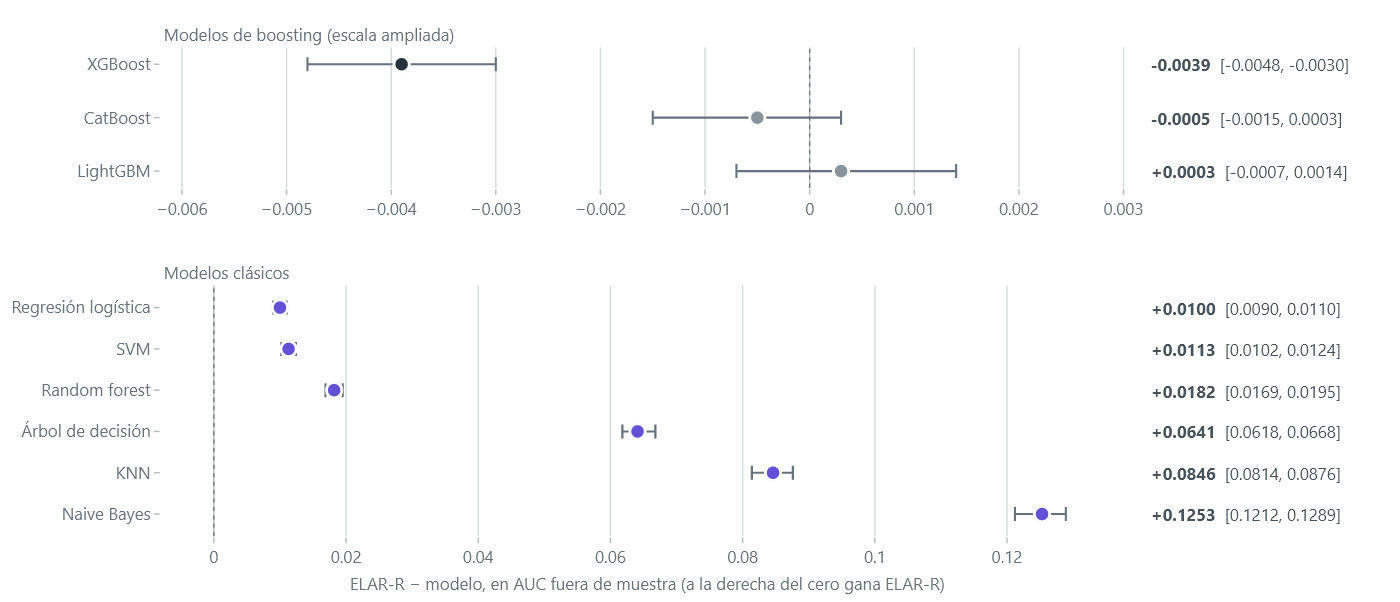

<small>Diferencia de AUC fuera de muestra, ELAR-R menos cada modelo, con su intervalo de confianza del 95 % (BCa). Violeta: ELAR-R supera. Tinta: el modelo supera a ELAR-R. Gris: el intervalo incluye el cero. Los dos paneles tienen escalas distintas. Fuente: entrega_persona3/tabla_lideres.csv.</small>

In [9]:
fig, titulo, nota = modelos.dibujar_forest(TEMA, None)
mostrar(fig, titulo, nota)

## 5. Página «Exploración EDA» (`/eda`)

Variables más determinantes (|SHAP| medio de XGBoost):

**«Puntaje externo 2» pesa más del doble que cualquier otra variable**

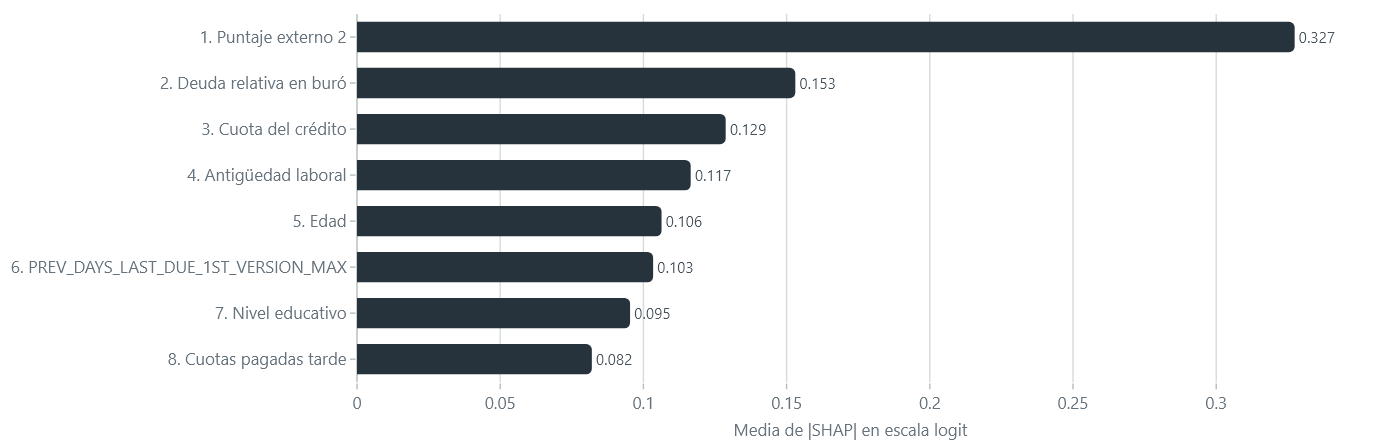

<small>Las 8 variables visibles con mayor media de |SHAP| de XGBoost; son las que se describen abajo. Fuente: dashboard_data/shap_global.json.</small>

In [10]:
mostrar(*eda.dibujar_importancia(TEMA))

Callback de los filtros (`actualizar`). Primero sin filtros: tarjetas, distribución de la variable más determinante, tasa de mora
por categoría y faltantes.

Solicitudes en la selección 246,008 100 % de las 246,008 del desarrollo.
Tasa de mora 8.07 % 19,860 solicitudes con dificultades de pago.
Frente al total 0.00 pp Puntos porcentuales sobre la mora total del desarrollo (8.07 %).
Riesgo relativo 1.00× Veces la tasa de mora general.
Sin filtros: 246,008 solicitudes del desarrollo y 8.07 % de mora.  Elija un filtro para ver en qué se aparta un subgrupo del total.


**Quien incumple tiene un valor más bajo de «Puntaje externo 2»: mediana cercana a 0.42 frente a 0.58**

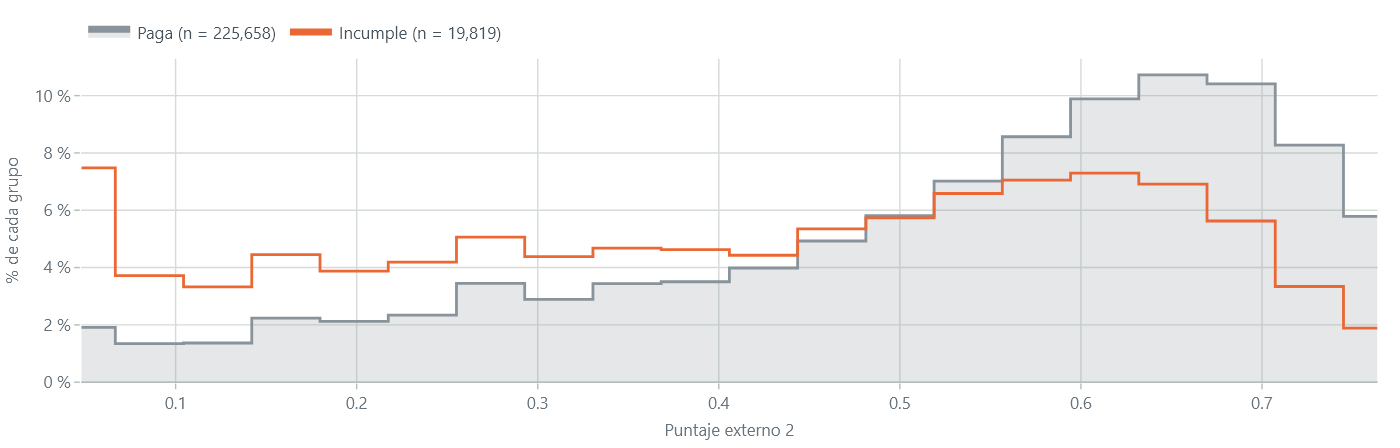

<small>Distribución: porcentaje de cada grupo por tramo, 246,008 solicitudes del desarrollo, entre los percentiles 1 y 99 (los faltantes no entran). Fuente: dashboard_data/eda_hist.csv.</small>

**Lower secondary tiene la mora más alta (11.1 %) y Academic degree la más baja (1.6 %)**

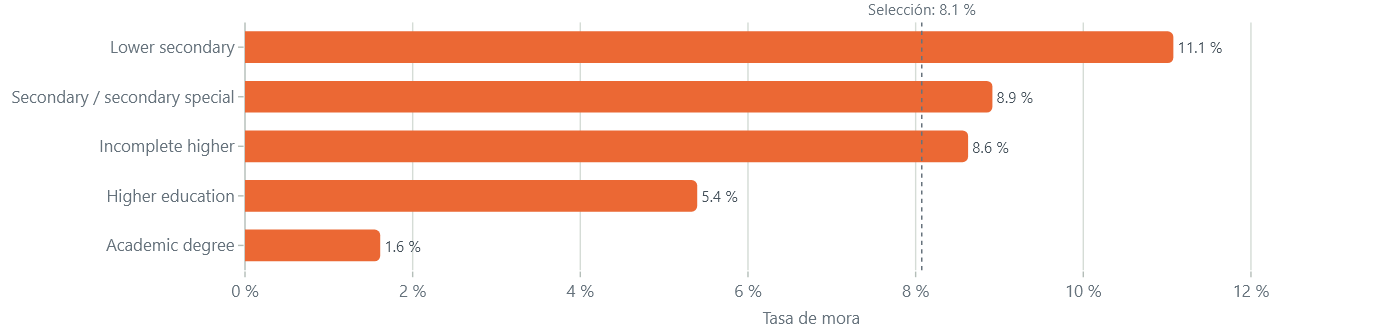

<small>Relación con la mora: tasa por nivel educativo, niveles con al menos 50 solicitudes. Fuente: dashboard_data/eda_categorias.csv.</small>

**3 de las 12 variables más vacías superan el 50 % de faltantes**

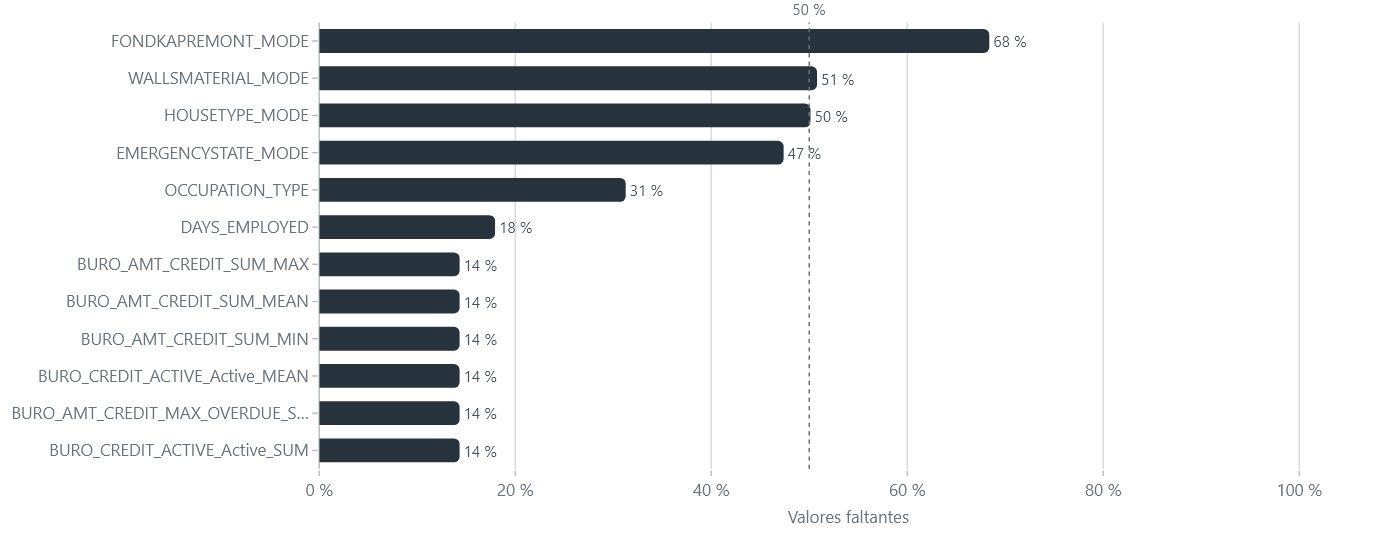

<small>Faltantes de la selección, en las 12 variables más vacías del desarrollo y las del histograma. Fuente: dashboard_data/eda_faltantes.csv.</small>

In [11]:
variable = next(iter(sv.datos_json("eda_bins.json")))
categoria = next(iter(eda.CATEGORIAS))
s = eda.actualizar("todos", "todos", "todos", "todos", variable, categoria, TEMA)
print(limpio(texto(s[9])))                      # tarjetas
print(limpio(texto(s[11])))                     # insight de la seleccion
mostrar(*s[0:3]); mostrar(*s[3:6]); mostrar(*s[6:9])

Con un filtro activo (créditos rotativos y edad menor de 30 años) el mismo callback recalcula todo:

Solicitudes en la selección 5,424 2 % de las 246,008 del desarrollo.
Tasa de mora 8.19 % 444 solicitudes con dificultades de pago.
Frente al total 0.11 pp Puntos porcentuales sobre la mora total del desarrollo (8.07 %).
Riesgo relativo 1.01× Veces la tasa de mora general.
5,424 solicitudes (2.2 % del desarrollo) con 8.19 % de mora , 0.11 puntos por encima del total (8.07 %). Es 1.01 veces la tasa general.


**Quien incumple tiene un valor más bajo de «Puntaje externo 2»: mediana cercana a 0.39 frente a 0.50**

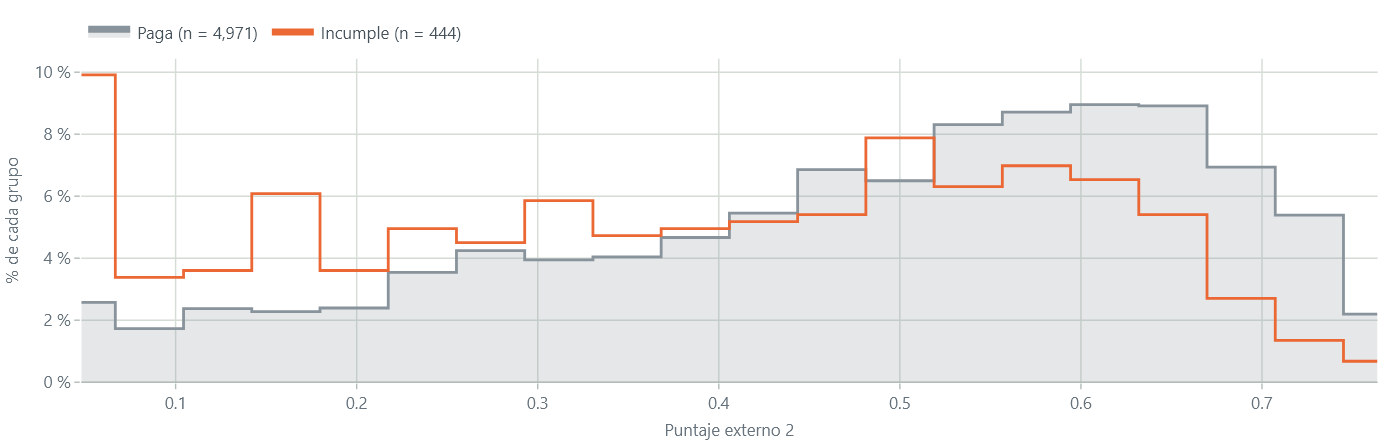

<small>Distribución: porcentaje de cada grupo por tramo, 5,424 solicitudes del desarrollo, entre los percentiles 1 y 99 (los faltantes no entran). Fuente: dashboard_data/eda_hist.csv.</small>

**Working tiene la mora más alta (8.8 %) y State servant la más baja (5.2 %)**

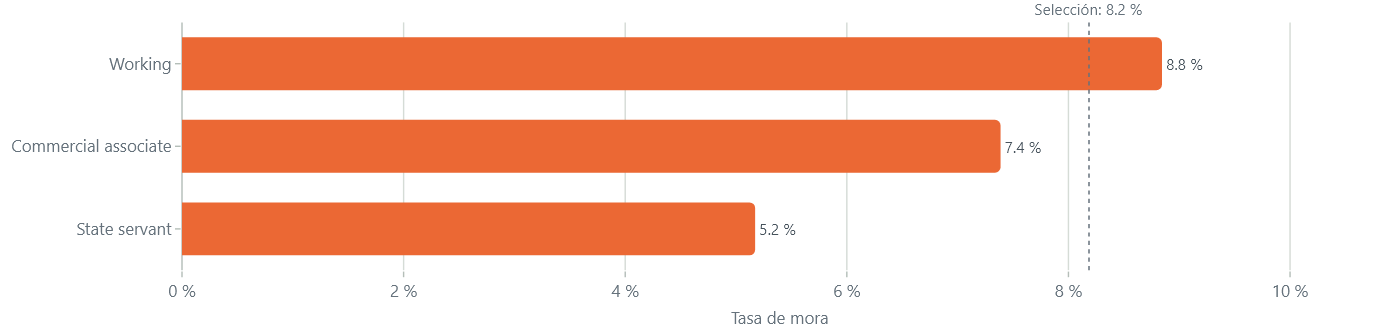

<small>Relación con la mora: tasa por tipo de ingreso, niveles con al menos 50 solicitudes. Fuente: dashboard_data/eda_categorias.csv.</small>

In [12]:
s = eda.actualizar("Revolving loans", "todos", "<30", "todos", variable, "NAME_INCOME_TYPE", TEMA)
print(limpio(texto(s[9])))
print(limpio(texto(s[11])))
mostrar(*s[0:3]); mostrar(*s[3:6])

**Relaciones débiles: ninguna de estas variables pasa de |ρ| = 0.15 con la mora; la más asociada es «Puntaje externo 2»**

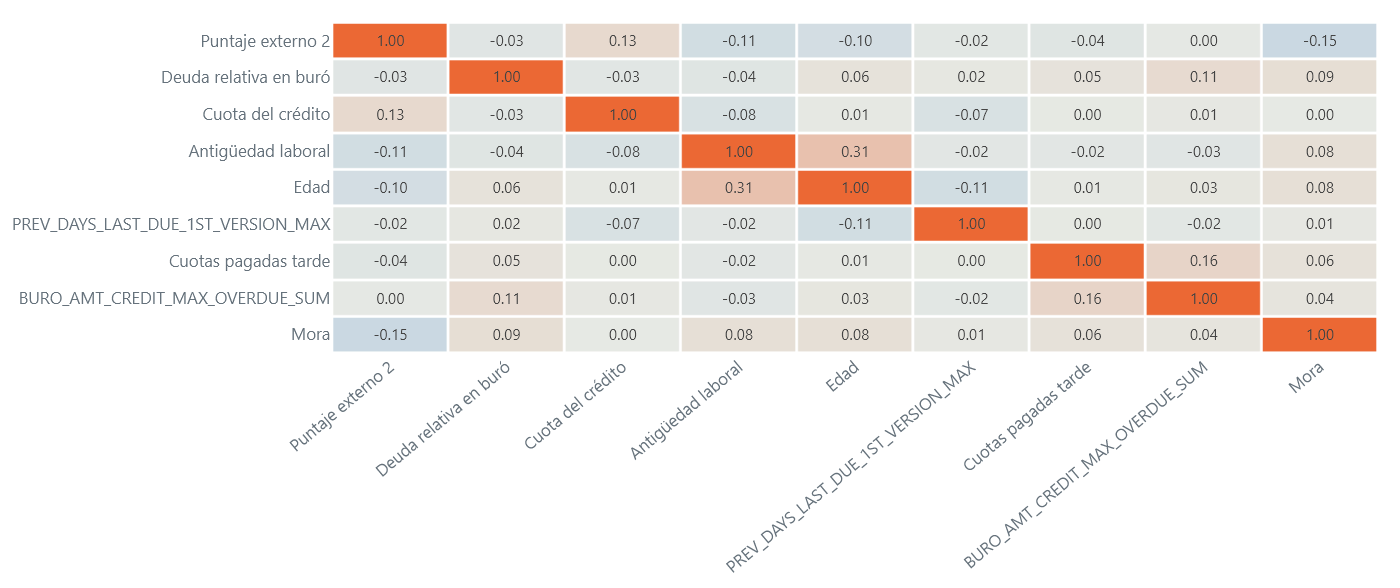

<small>Relaciones entre variables: correlación de Spearman entre las variables numéricas principales y la mora, en todo el desarrollo; no cambia con los filtros. Fuente: dashboard_data/eda_correlaciones.csv.</small>

In [13]:
mostrar(*eda.dibujar_correlaciones(TEMA))

## 6. Página «Modelos & Predicción» (`/modelos`): resultados

Pestañas de la página:

In [14]:
lay = modelos.layout() if callable(modelos.layout) else modelos.layout
def pestanas(c, out):
    if isinstance(c, (list, tuple)):
        for x in c: pestanas(x, out)
    elif hasattr(c, "children") or hasattr(c, "label"):
        if type(c).__name__ == "Tab":
            out.append(f"{c.tab_id}: {c.label}")
        pestanas(getattr(c, "children", None), out)
    return out
print("\n".join(pestanas(lay, [])))

fundamentos: 1. Fundamentos de ELAR-R
diseno: 2. Diseño experimental
resultados: 3. Resultados
vivo: 4. Simulador


Callback `dibujar_resultados` de la pestaña «Resultados»: AUC entre conjuntos, valores p, calibración, predicción conforme,
robustez, degradación, diagrama de diferencia crítica y errores por subgrupo.

**ELAR-R tiene el mejor rango medio (2.25) y es el primero en German credit y Taiwan default**

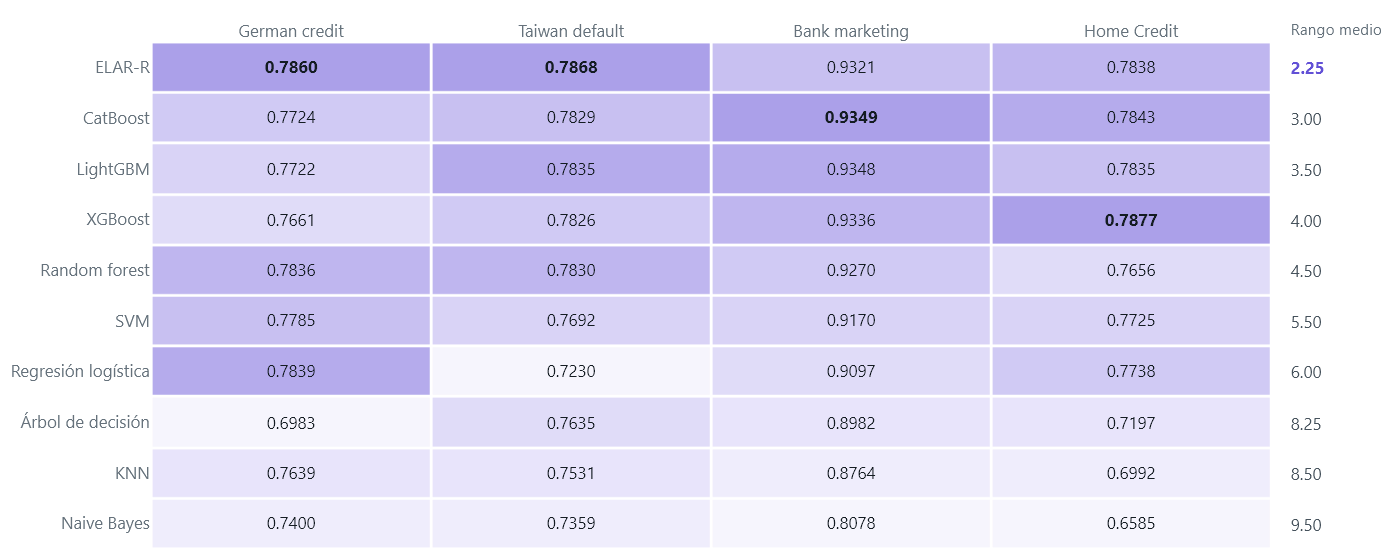

<small>Generalización a otros conjuntos: AUC medio de las validaciones externas (en Home Credit, el AUC con las predicciones fuera de muestra unidas). El color es el puesto dentro de cada conjunto. Fuente: entrega_persona3/matriz_auc_conjuntos.csv.</small>

**En Bank marketing ELAR-R pierde frente a CatBoost y LightGBM en las 5 repeticiones: la hipótesis H2 no se cumple**

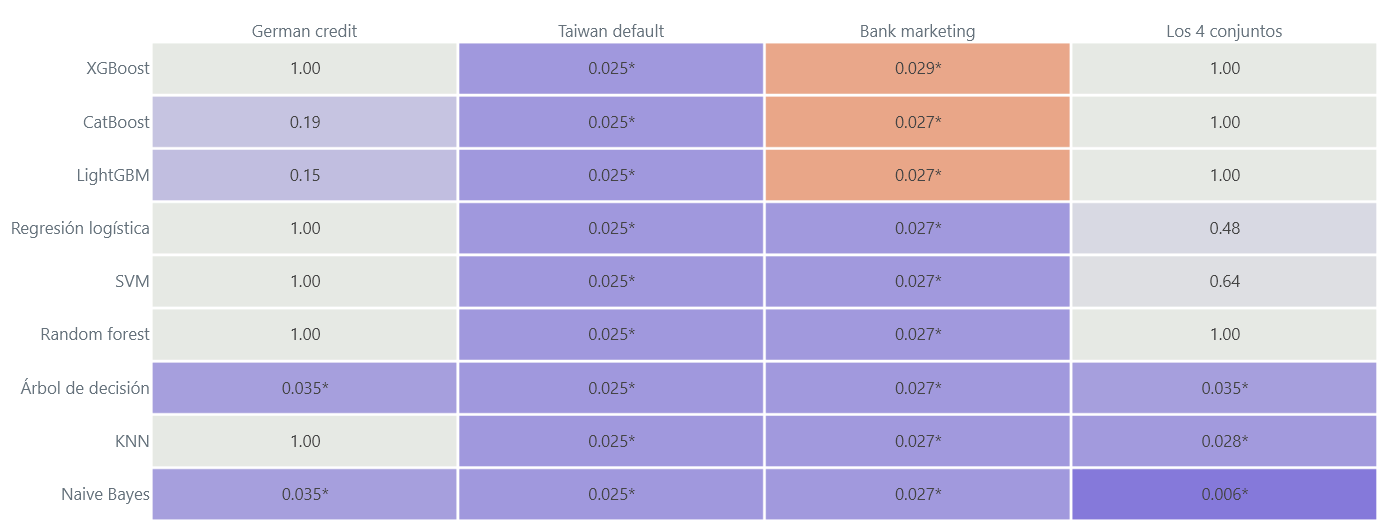

<small>Valor p con ajuste de Holm de ELAR-R frente a cada modelo. Violeta: ELAR-R mejor. Naranja: ELAR-R peor. El asterisco marca p < 0.05. Por conjunto, Wilcoxon; en los 4 conjuntos, post hoc de Friedman con Holm. Fuentes: pruebas_por_conjunto.csv y posthoc_entre_conjuntos.csv.</small>

**Sin calibrar, Regresión logística, Naive Bayes, Random forest se desvían entre 0.27 y 0.32; con la isotónica todos quedan bajo 0.004**

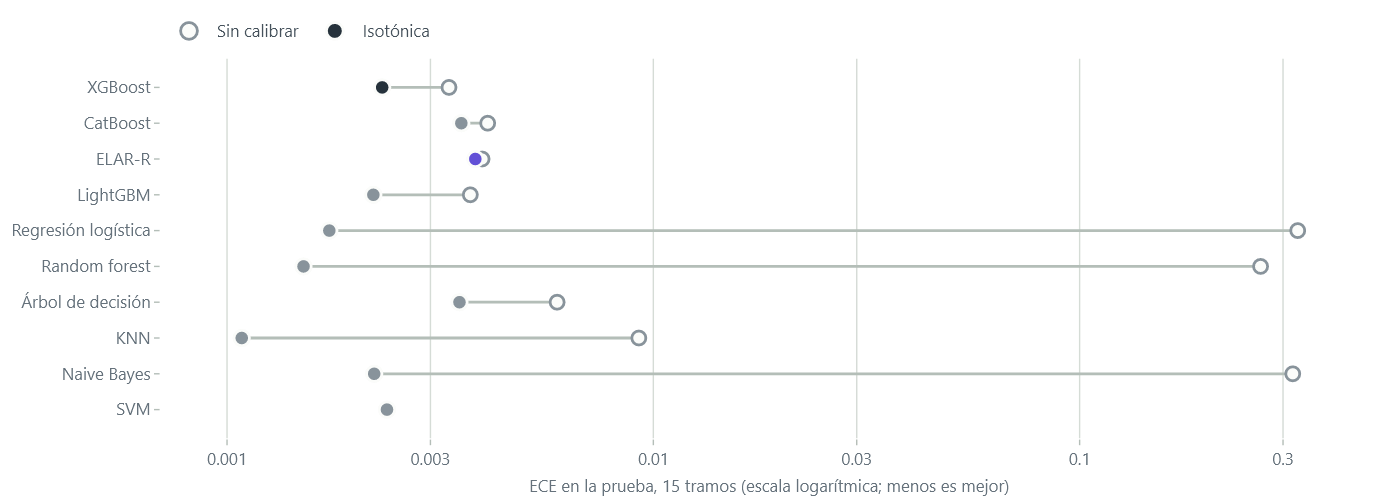

<small>Error de calibración esperado en la prueba, antes y después de calibrar con las predicciones fuera de muestra. SVM no entrega probabilidades sin calibrar. Fuente: entrega_persona3/calibracion.csv.</small>

**La cobertura real va de 88.4 % a 99.2 % frente al 90 % nominal, y entre 44 % y 80 % de los casos quedan como inciertos**

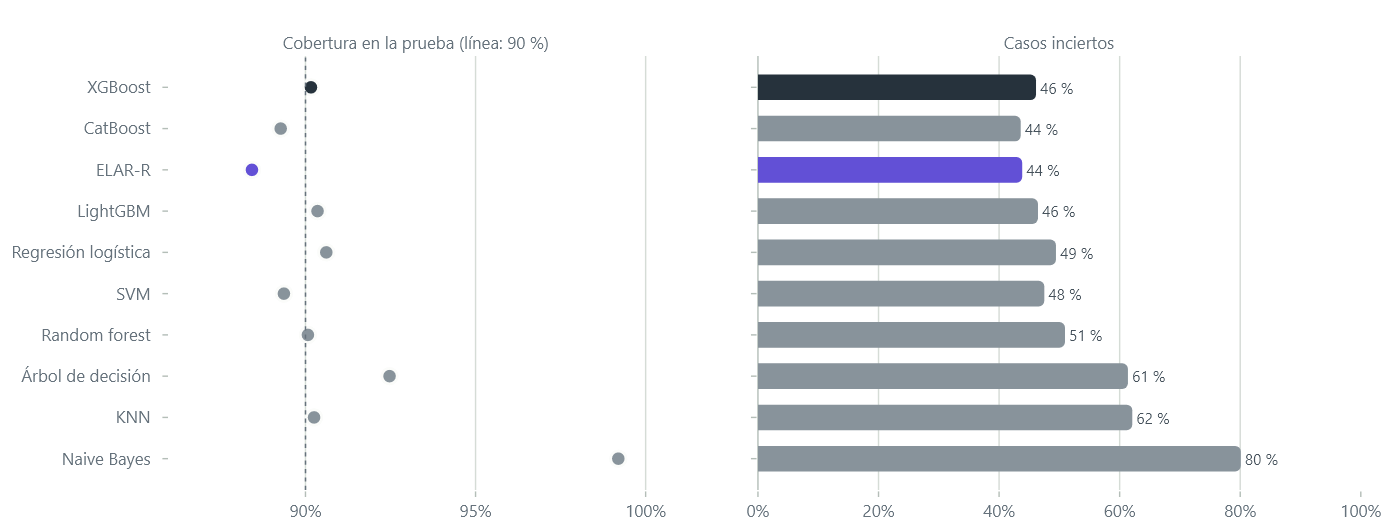

<small>Predicción conforme Mondrian por clase al 90 %, calibrada con las predicciones fuera de muestra. Fuente: entrega_persona3/conformal.csv.</small>

**Entre los cuatro modelos de mayor AUC, ELAR-R es el más estable (desviación entre semillas 0.0005) y tarda 8.7 veces lo que XGBoost**

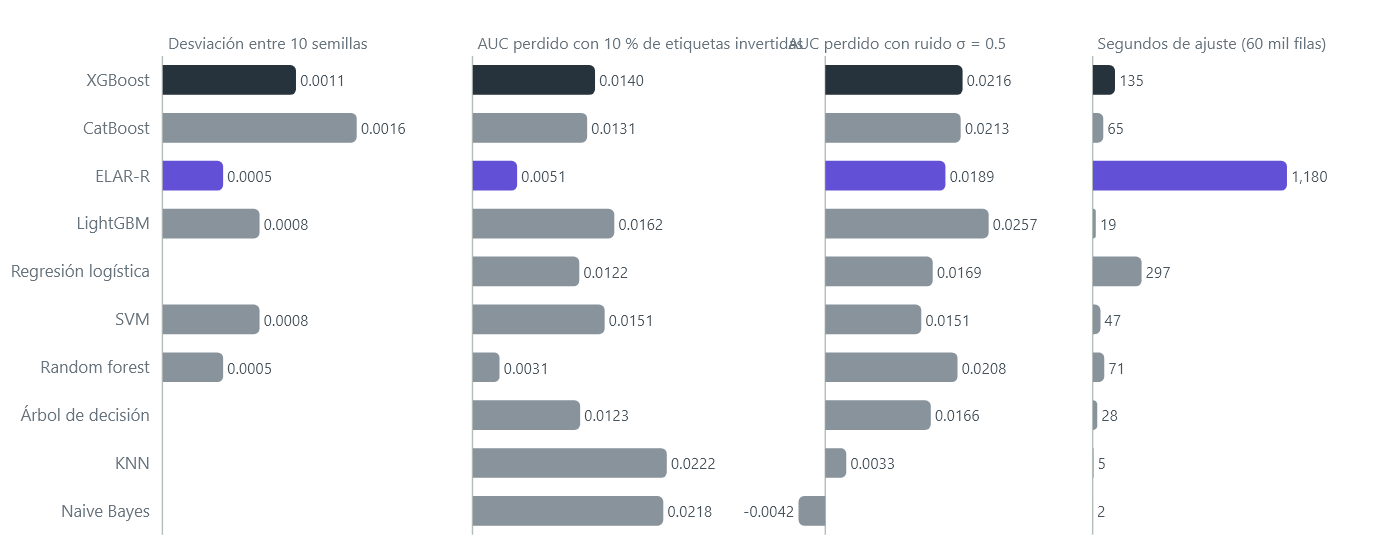

<small>Estabilidad: pliegue externo 0 con 60 mil filas de entrenamiento. Los modelos deterministas no tienen desviación entre semillas (sin barra). Random forest iguala a ELAR-R en semillas y pierde menos con etiquetas invertidas, pero con menor AUC. Fuente: entrega_persona3/robustez_resumen.csv.</small>

**Sin sobreajuste: entre la validación externa y la prueba ningún modelo cambia más de 0.006 de AUC**

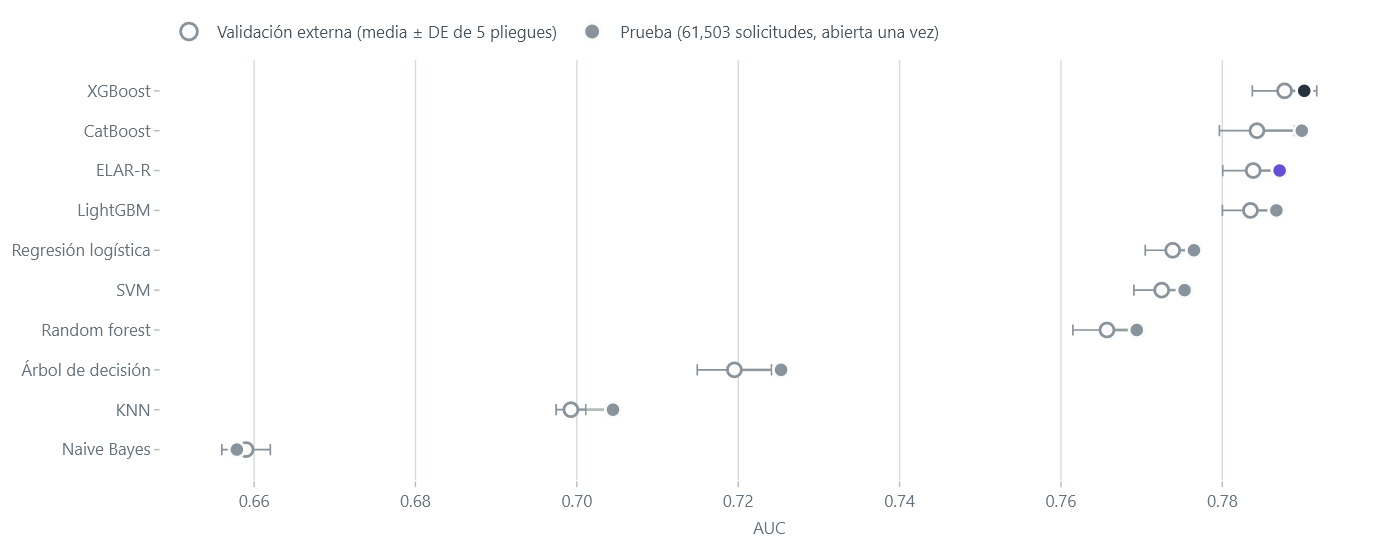

<small>Si un modelo hubiera sobreajustado a los datos con que se eligió, su AUC caería en la prueba, que no participó en ninguna decisión. Fuente: entrega_persona3/distribucion.csv.</small>

**Con Nemenyi (CD = 6.77) ELAR-R solo se separa de Naive Bayes; con el post hoc de Holm, también de Árbol de decisión y KNN**

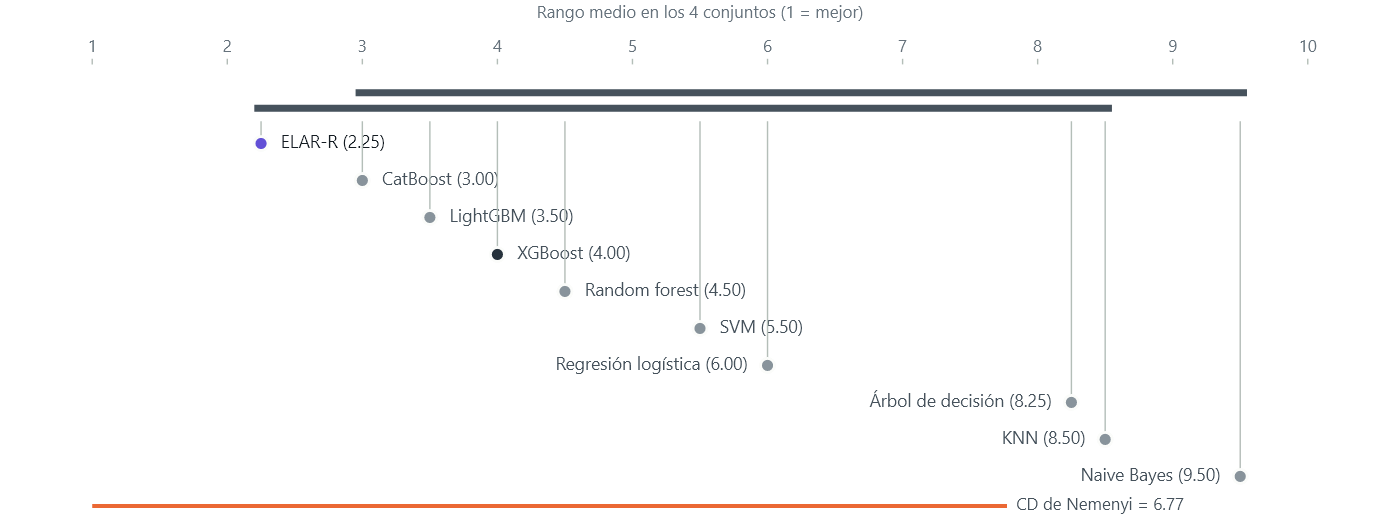

<small>Diagrama de diferencia crítica (Demšar, 2006) con los rangos medios en 4 conjuntos. Una barra gris une modelos que Nemenyi no distingue. Fuentes: matriz_auc_conjuntos.csv, resultados_e4/f7_estadistica/resumen.json (CD) y posthoc_entre_conjuntos.csv.</small>

**ELAR-R queda por debajo de XGBoost en 13 de 15 subgrupos; en 3 la diferencia es significativa**

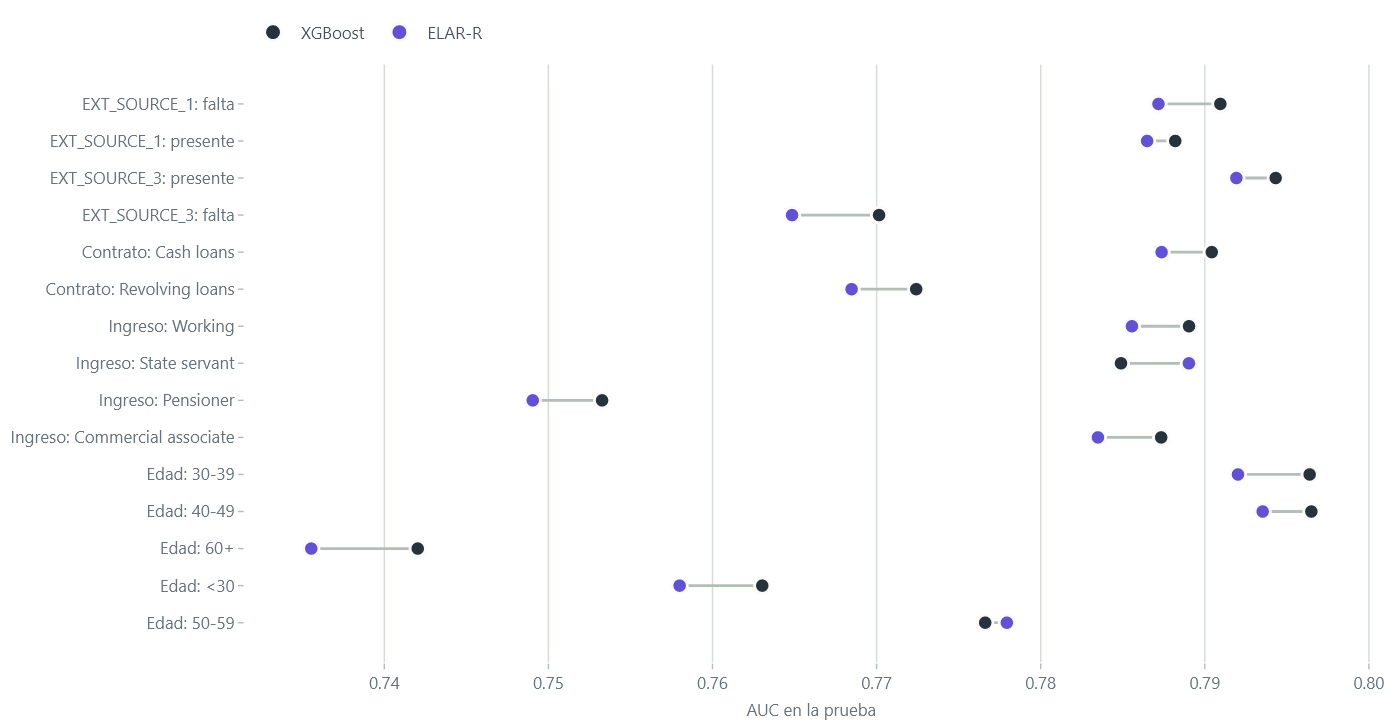

<small>AUC en la prueba por subgrupo. Cada fila es un filtro por separado: no hay cruces. DeLong con ajuste de Holm. Fuente: entrega_persona3/errores_subgrupo.csv.</small>

Los subgrupos más difíciles para ELAR-R:  Edad: 60+ (0.736); Ingreso: Pensioner (0.749); Edad: <30 (0.758); EXT_SOURCE_3: falta (0.765) .
Los créditos rotativos son más difíciles (AUC 0.768 frente a 0.787 en efectivo): son 5,831 de 61,503 y con menos mora (5.4 %), así que hay menos casos de los que aprender.
Con la predicción conforme al 90 %, el 44 % de las solicitudes queda con las dos clases posibles: para ellas el modelo no decide con confianza. Por eso apoya a un analista y no lo reemplaza.
Fuentes: errores_subgrupo.csv y conformal.csv.


In [15]:
s = modelos.dibujar_resultados(TEMA, "resultados")
for i in range(0, 24, 3):
    mostrar(*s[i:i + 3])
print(limpio(texto(s[24])))

Diagrama de confiabilidad (callback `dibujar_confiabilidad`), para la regresión logística:

**Regresión logística: el error de calibración pasa de 0.325 a 0.0017 con la isotónica**

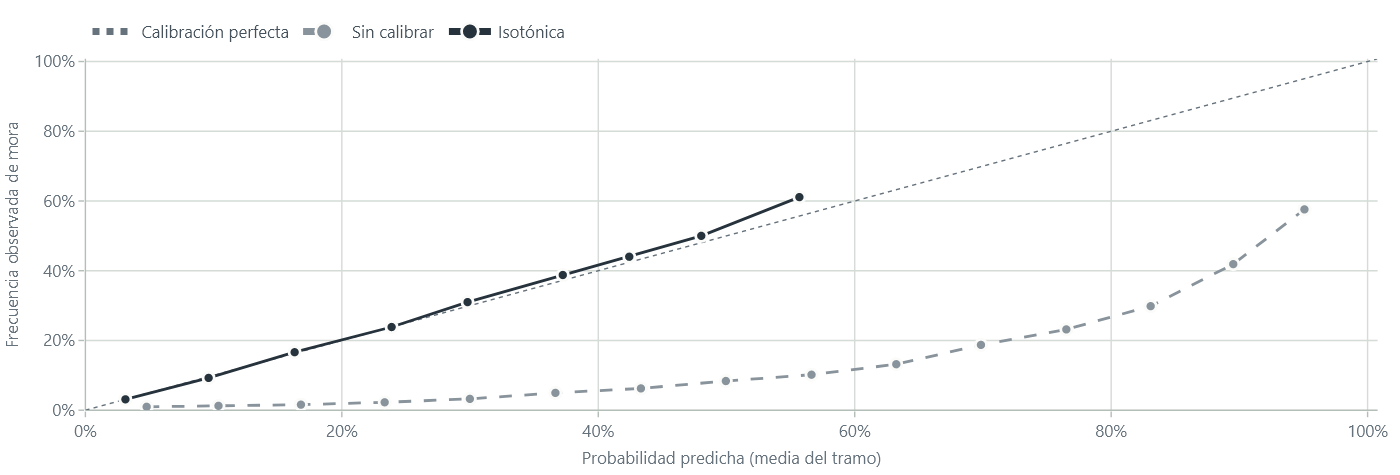

<small>Diagrama de confiabilidad: sobre la diagonal, lo que el modelo predice es lo que ocurre. Por eso el simulador muestra la probabilidad isotónica. Fuente: entrega_persona3/curvas_calibracion.csv.</small>

In [16]:
mostrar(*modelos.dibujar_confiabilidad("logistica", TEMA))

Desempeño en la prueba (callback `dibujar_desempeno`): curvas ROC y PR, matriz de confusión de XGBoost y SHAP global.

**El XGBoost que predice aquí es el del Entregable 3: AUC 0.7754 con 483 entradas, no el 0.7902 de la tabla de líderes**

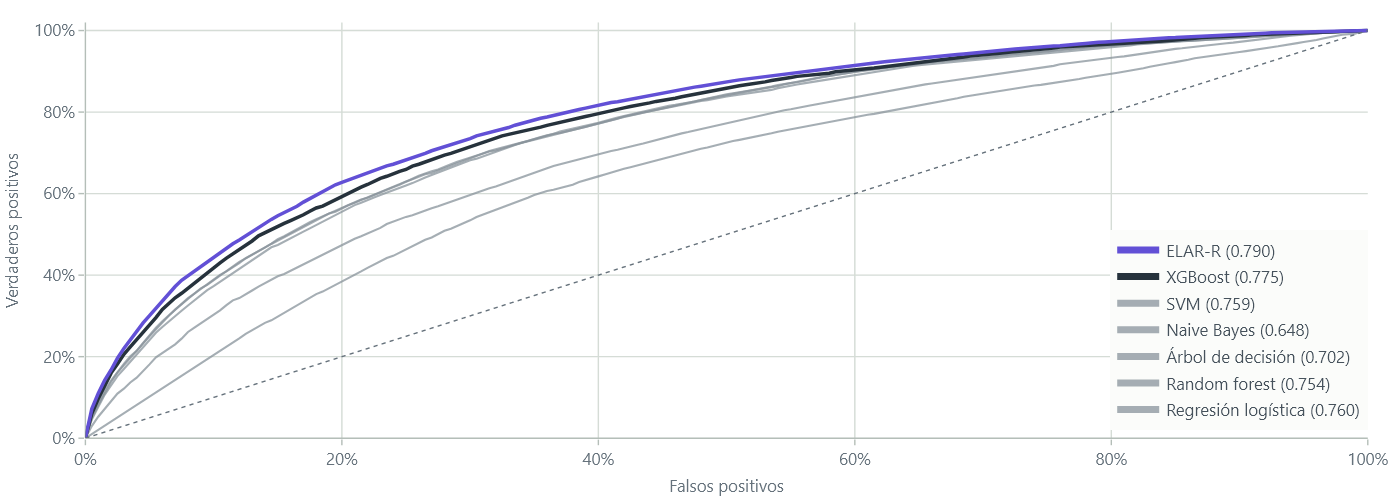

<small>Curvas ROC de los modelos servidos, en la prueba; entre paréntesis, su AUC. ELAR-R usa además 83 variables de historial, por eso no es comparable con los demás aquí. Fuente: dashboard_data/curvas.json.</small>

**Para detectar la mitad de los incumplimientos, la precisión es de 24 % con XGBoost y 26 % con ELAR-R**

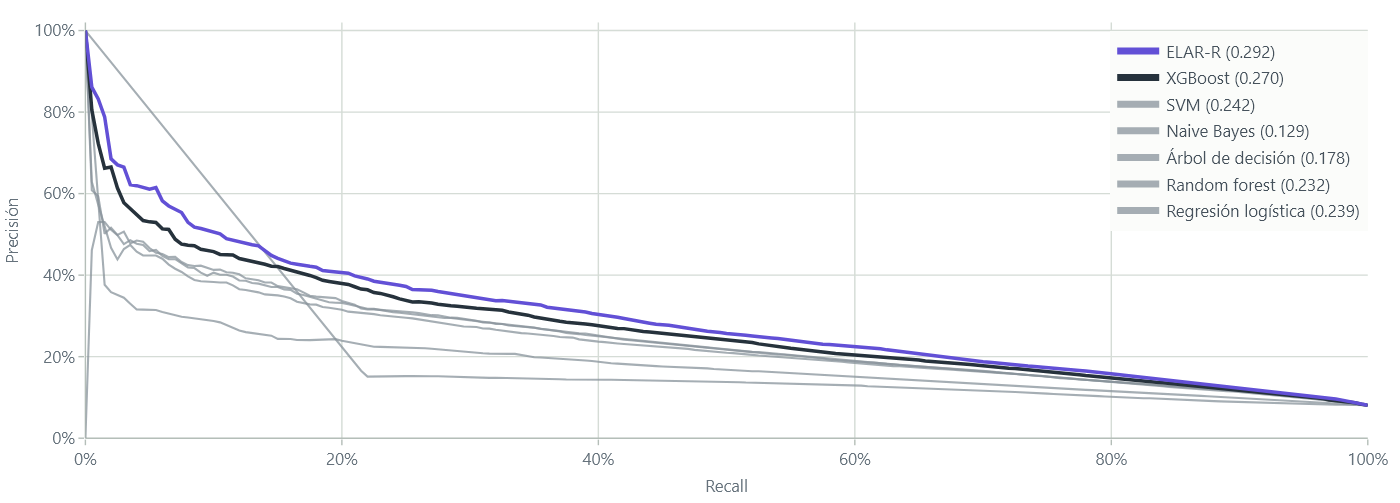

<small>Curvas de precisión y recall en la prueba; entre paréntesis, la precisión media. Con cerca de 8 % de positivos, la precisión es baja para todos. Fuente: dashboard_data/curvas.json.</small>

**Con su umbral de coste, XGBoost detecta 67 % de los incumplimientos y rechaza a 25 % de quienes pagan**

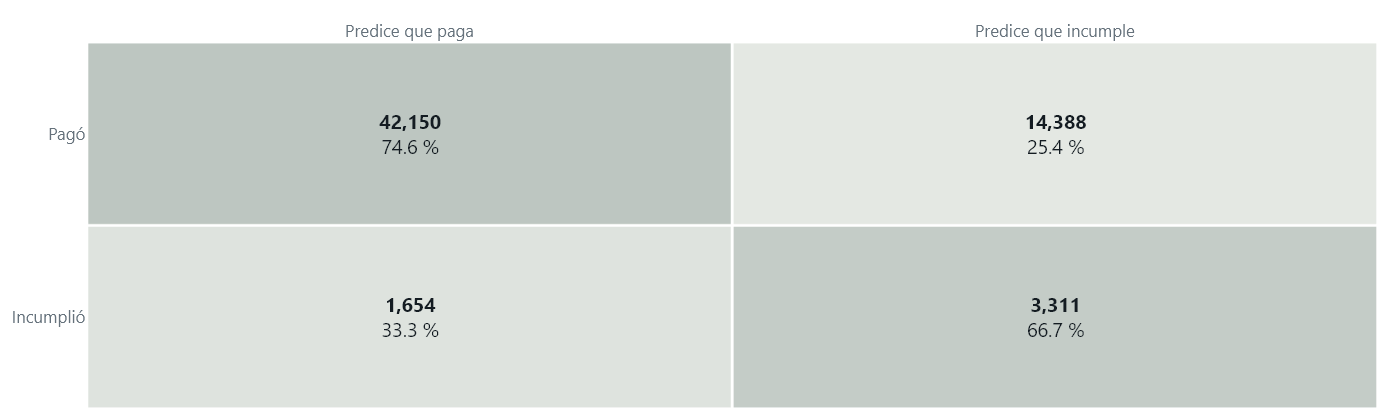

<small>Matriz de confusión en la prueba (n = 61,503) con el umbral 0.0894. Coste total: 30,928 (10 por cada falso negativo y 1 por cada falso positivo). Fuente: dashboard_data/curvas.json.</small>

**«Puntaje externo 2» es la variable que más mueve la predicción de XGBoost**

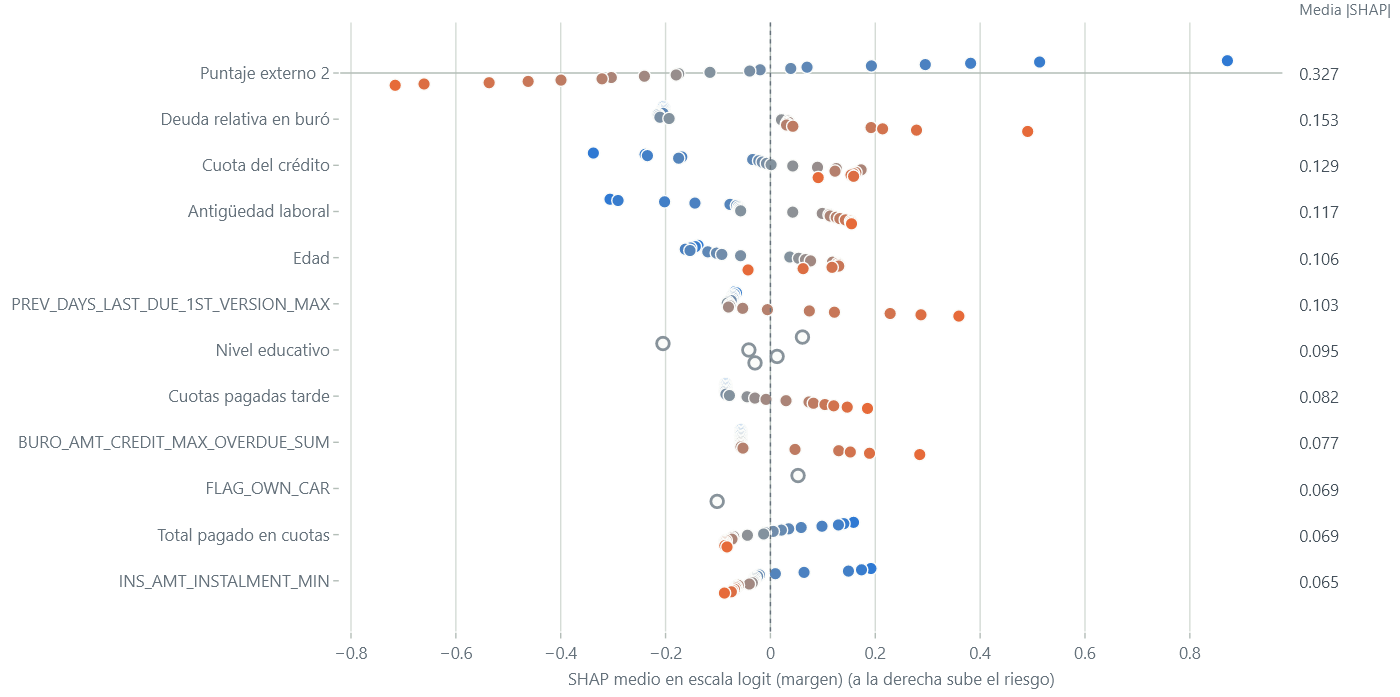

<small>Interpretación: SHAP exacto de XGBoost en 20,000 solicitudes del desarrollo. Cada marca es un veintil del valor de la variable (azul: valores bajos; naranja: altos); los círculos huecos son niveles de variables categóricas. No se muestran variables sensibles. Fuente: dashboard_data/shap_global.json.</small>

In [17]:
s = modelos.dibujar_desempeno("xgboost", TEMA)
for i in range(0, 12, 3):
    mostrar(*s[i:i + 3])

## 7. Simulador

El formulario expone las variables que más pesan en XGBoost; las demás columnas quedan en el perfil base (mediana o moda del
desarrollo). Valores por defecto y rangos permitidos:

In [18]:
campos = sv.formulario()["campos"]
pd.DataFrame([{"variable": c["etiqueta"], "columna": c["columna"], "tipo": c["tipo"],
               "rango o niveles": (", ".join(c["niveles"][:4]) + (" …" if len(c["niveles"]) > 4 else "")) if c["tipo"] == "categorica"
                                  else "{:,.{d}f} a {:,.{d}f}".format(*sv.rango_visible(c), d=c["decimales"]),
               "por defecto": c["defecto"] if c["tipo"] == "categorica" else sv.valor_visible(c)} for c in campos]).set_index("variable")

,columna,tipo,rango o niveles,por defecto
variable,,,,
Puntaje externo 2,EXT_SOURCE_2,numerica,0.03 a 0.78,0.57
Deuda relativa en buró,BURO_DEUDA_REL_SUM,numerica,0.00 a 4.84,0.82
Cuota del crédito,AMT_ANNUITY,numerica,"6,188 a 70,030",24903.0
Antigüedad laboral,DAYS_EMPLOYED,numerica,0.3 a 31.0,4.5
Edad,DAYS_BIRTH,numerica,22.6 a 66.8,43.1
PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,numerica,"-1,561 a 2,379",-12.0
Nivel educativo,NAME_EDUCATION_TYPE,categorica,"Secondary / secondary special, Higher educatio...",Secondary / secondary special
Cuotas pagadas tarde,INS_PAGO_TARDE_MEAN,numerica,0.00 a 0.50,0.02
BURO_AMT_CREDIT_MAX_OVERDUE_SUM,BURO_AMT_CREDIT_MAX_OVERDUE_SUM,numerica,"0 a 78,610",0.0


Se pulsa «Calcular riesgo» con el perfil base y XGBoost (callback `predecir` de la página):

Probabilidad calibrada (isotónica) de incumplir
4.2 %
✓ Bajo el umbral de coste
Umbral 9.6 %
0 % 30 % 60 %
Umbral de coste, en escala calibrada Franja incierta de la predicción conforme
Etiqueta conforme:  incierto . Es decir, el conjunto de predicción contiene las dos clases; el modelo no puede descartar ninguna.
El puntaje de XGBoost (0.0480)  no alcanza  su umbral de coste (0.0894), elegido para que un incumplimiento no detectado pese 10 rechazos de buenos clientes. El modelo ordena y explica; la decisión exige revisión humana.
Modelo: ganador del Entregable 3 con 483 entradas (AUC en la prueba 0.7754, artifacts/metadata.json).  Calibrador: predicciones fuera de muestra de las 246,008 solicitudes del desarrollo: validación externa de la validación anidada del E3 (5 pliegues; hiperparámetros elegidos dentro de cada pliegue).


**«Puntaje externo 2» es lo que más baja el riesgo de esta solicitud**

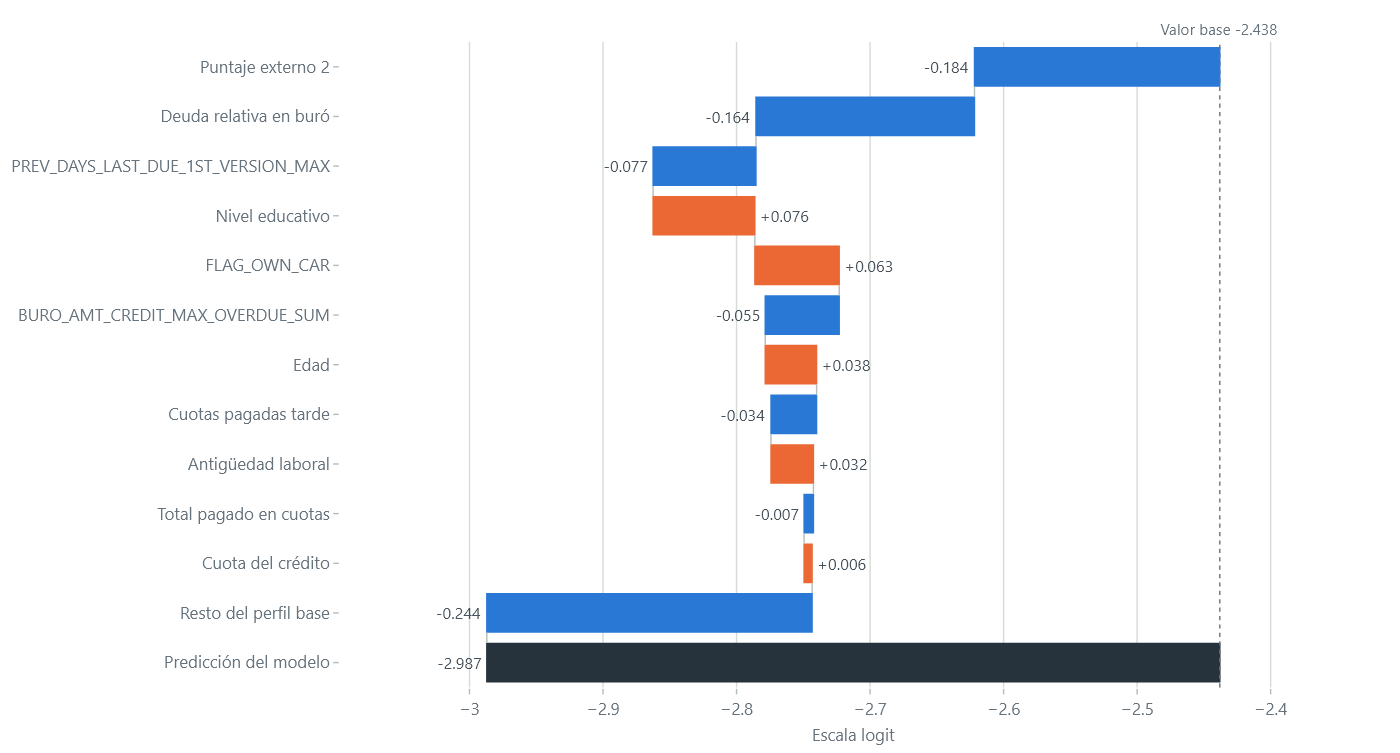

<small>Contribución de cada variable del formulario en escala logit: naranja sube el riesgo y azul lo baja. La probabilidad de arriba es la calibrada, no esta escala. Método: TreeSHAP exacto de XGBoost (pred_contribs), equivalente a TreeExplainer.</small>

In [19]:
ids = [{"type": "mod-campo", "columna": c["columna"]} for c in campos]
base = [c["defecto"] if c["tipo"] == "categorica" else sv.valor_visible(c) for c in campos]

def calcular(modelo, valores):
    resultado, fig, titulo, nota = modelos.predecir(1, modelo, TEMA, valores, ids)
    print(limpio(texto(resultado)))
    mostrar(fig, titulo, nota)

calcular("xgboost", base)

Una solicitud más riesgosa: puntaje externo 2 bajo y la mitad de las cuotas pagadas tarde.

Probabilidad calibrada (isotónica) de incumplir
16.6 %
! Sobre el umbral de coste
Umbral 9.6 %
0 % 30 % 60 %
Umbral de coste, en escala calibrada Franja incierta de la predicción conforme
Etiqueta conforme:  riesgo alto . Es decir, con 90 % de confianza, el conjunto de predicción solo contiene «incumple».
El puntaje de XGBoost (0.1476)  alcanza  su umbral de coste (0.0894), elegido para que un incumplimiento no detectado pese 10 rechazos de buenos clientes. El modelo ordena y explica; la decisión exige revisión humana.
Modelo: ganador del Entregable 3 con 483 entradas (AUC en la prueba 0.7754, artifacts/metadata.json).  Calibrador: predicciones fuera de muestra de las 246,008 solicitudes del desarrollo: validación externa de la validación anidada del E3 (5 pliegues; hiperparámetros elegidos dentro de cada pliegue).


**«Puntaje externo 2» es lo que más sube el riesgo de esta solicitud**

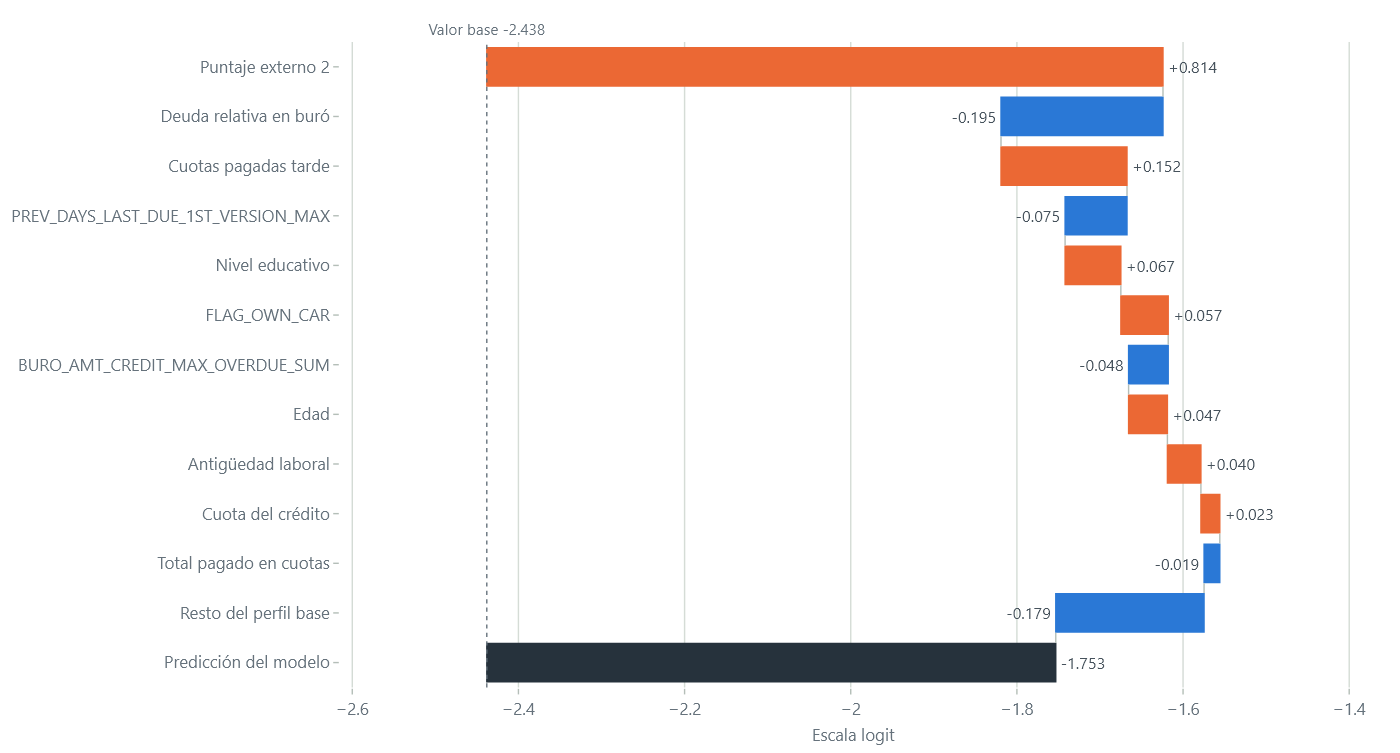

<small>Contribución de cada variable del formulario en escala logit: naranja sube el riesgo y azul lo baja. La probabilidad de arriba es la calibrada, no esta escala. Método: TreeSHAP exacto de XGBoost (pred_contribs), equivalente a TreeExplainer.</small>

In [20]:
riesgosa = list(base)
for i, c in enumerate(campos):
    lo, hi = sv.rango_visible(c) if c["tipo"] != "categorica" else (None, None)
    if c["columna"] == "EXT_SOURCE_2":
        riesgosa[i] = round(lo + 0.1 * (hi - lo), c["decimales"])
    if c["columna"] == "INS_PAGO_TARDE_MEAN":
        riesgosa[i] = round(lo + 0.5 * (hi - lo), c["decimales"])
calcular("xgboost", riesgosa)

Los seis modelos que predicen en vivo, sobre el perfil base y sobre la solicitud riesgosa:

In [21]:
filas = []
for nombre_perfil, valores in (("perfil base", base), ("solicitud riesgosa", riesgosa)):
    entradas = {i["columna"]: v for i, v in zip(ids, valores)}
    for m in sv.VIVOS:
        p = sv.predecir(m, entradas)
        filas.append({"perfil": nombre_perfil, "modelo": th.nombre_modelo(m), "puntaje": round(p["puntaje"], 4),
                      "umbral de coste": round(p["umbral"], 4),
                      "prob. calibrada": None if p["calibrada"] is None else round(p["calibrada"], 4),
                      "decisión": "sobre el umbral" if p["decision"] else "bajo el umbral", "conforme": p["conformal"]})
pd.DataFrame(filas).set_index(["perfil", "modelo"])

puntaje  umbral de coste  \
perfil             modelo                                          
perfil base        XGBoost               0.0480           0.0894   
                   Regresión logística   0.3361           0.5221   
                   Random forest         0.3430           0.3841   
                   Árbol de decisión     0.0429           0.0917   
                   Naive Bayes           0.0024           0.9439   
                   SVM                  -0.3181           0.0294   
solicitud riesgosa XGBoost               0.1476           0.0894   
                   Regresión logística   0.5918           0.5221   
                   Random forest         0.5115           0.3841   
                   Árbol de decisión     0.2113           0.0917   
                   Naive Bayes           0.0209           0.9439   
                   SVM                   0.1548           0.0294   

                                        prob. calibrada         decisión  \
perfil             modelo                                                  
perfil base        XGBoost                       0.0422   bajo el umbral   
                   Regresión logística           0.0410   bajo el umbral   
                   Random forest                 0.0694   bajo el umbral   
                   Árbol de decisión             0.0470   bajo el umbral   
                   Naive Bayes                   0.0662   bajo el umbral   
                   SVM                           0.0404   bajo el umbral   
solicitud riesgosa XGBoost                       0.1656  sobre el umbral   
                   Regresión logística           0.1197  sobre el umbral   
                   Random forest                 0.1681  sobre el umbral   
                   Árbol de decisión             0.1956  sobre el umbral   
                   Naive Bayes                   0.0694   bajo el umbral   
                   SVM                           0.1156  sobre el umbral   

                                           conforme  
perfil             modelo                            
perfil base        XGBoost                 incierto  
                   Regresión logística     incierto  
                   Random forest           incierto  
                   Árbol de decisión       incierto  
                   Naive Bayes             incierto  
                   SVM                     incierto  
solicitud riesgosa XGBoost              riesgo alto  
                   Regresión logística     incierto  
                   Random forest           incierto  
                   Árbol de decisión    riesgo alto  
                   Naive Bayes             incierto  
                   SVM                     incierto

Validación de entradas: un valor fuera de rango no se predice, se explica el error.

Hay entradas fuera de rango o vacías.
Puntaje externo 2: 5.00 está fuera del rango 0.03 a 0.78.


**Sin predicción**

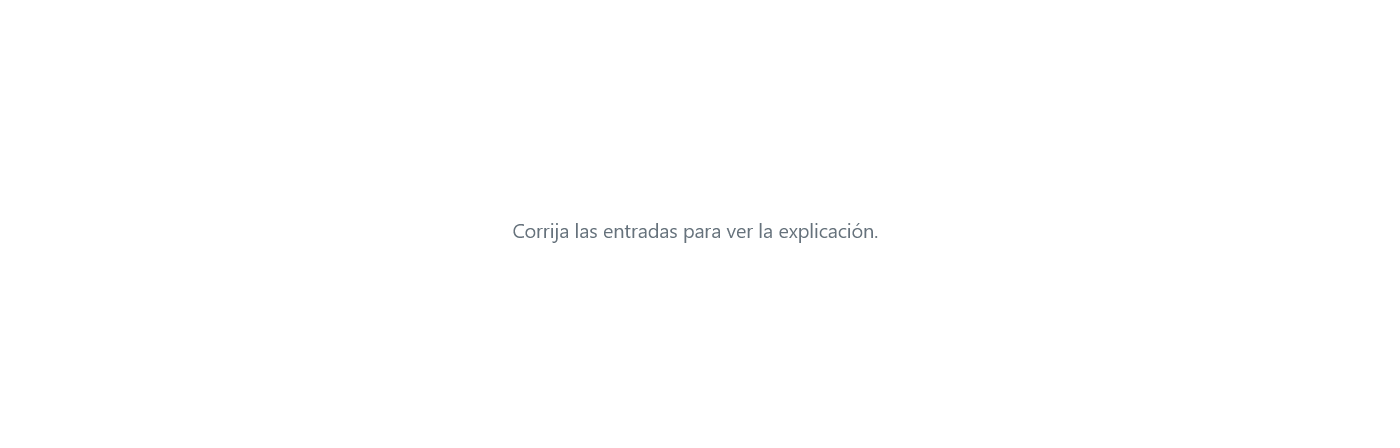

<small>Corrija las entradas marcadas.</small>

In [22]:
malo = list(base)
malo[0] = 5.0                                   # puntaje externo 2 fuera de [0, 1]
calcular("xgboost", malo)

ELAR-R necesita 83 variables de historial que un formulario no puede dar, así que el dashboard muestra casos reales de la
prueba con su predicción calibrada y sus contribuciones exactas (callback `mostrar_caso`):

In [23]:
casos = sv.datos_json("casos_elar.json")["casos"]
pd.DataFrame([{"caso": k["id"], "prob. calibrada": round(k["prob_calibrada"], 4), "decisión": k["decision"],
               "conforme": k["conformal"], "real": "incumplió" if k["real"] else "pagó"} for k in casos]).set_index("caso").T

caso,Caso 1,Caso 2,Caso 3,Caso 4,Caso 5,Caso 6,Caso 7,Caso 8,Caso 9,Caso 10,Caso 11,Caso 12,Caso 13,Caso 14,Caso 15,Caso 16,Caso 17,Caso 18,Caso 19,Caso 20
prob. calibrada,0.0088,0.0092,0.0136,0.0183,0.0183,0.0243,0.0302,0.0318,0.0397,0.0462,0.047,0.0615,0.0719,0.0874,0.0961,0.123,0.1474,0.1791,0.2412,0.5651
decisión,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1
conforme,riesgo bajo,riesgo bajo,riesgo bajo,riesgo bajo,riesgo bajo,riesgo bajo,riesgo bajo,riesgo bajo,incierto,incierto,incierto,incierto,incierto,incierto,incierto,incierto,incierto,riesgo alto,riesgo alto,riesgo alto
real,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó,pagó


### Caso 10

Probabilidad calibrada (isotónica) de incumplir
4.6 %
✓ Bajo el umbral de coste
Etiqueta conforme:  incierto . Es decir, el conjunto de predicción contiene las dos clases; el modelo no puede descartar ninguna.
En la prueba, esta persona  pagó .
Umbral de coste interno de ELAR-R: 0.0912 sobre la probabilidad sin calibrar (0.0436).


**En este caso, «INS_COUNT» es lo que más baja el riesgo**

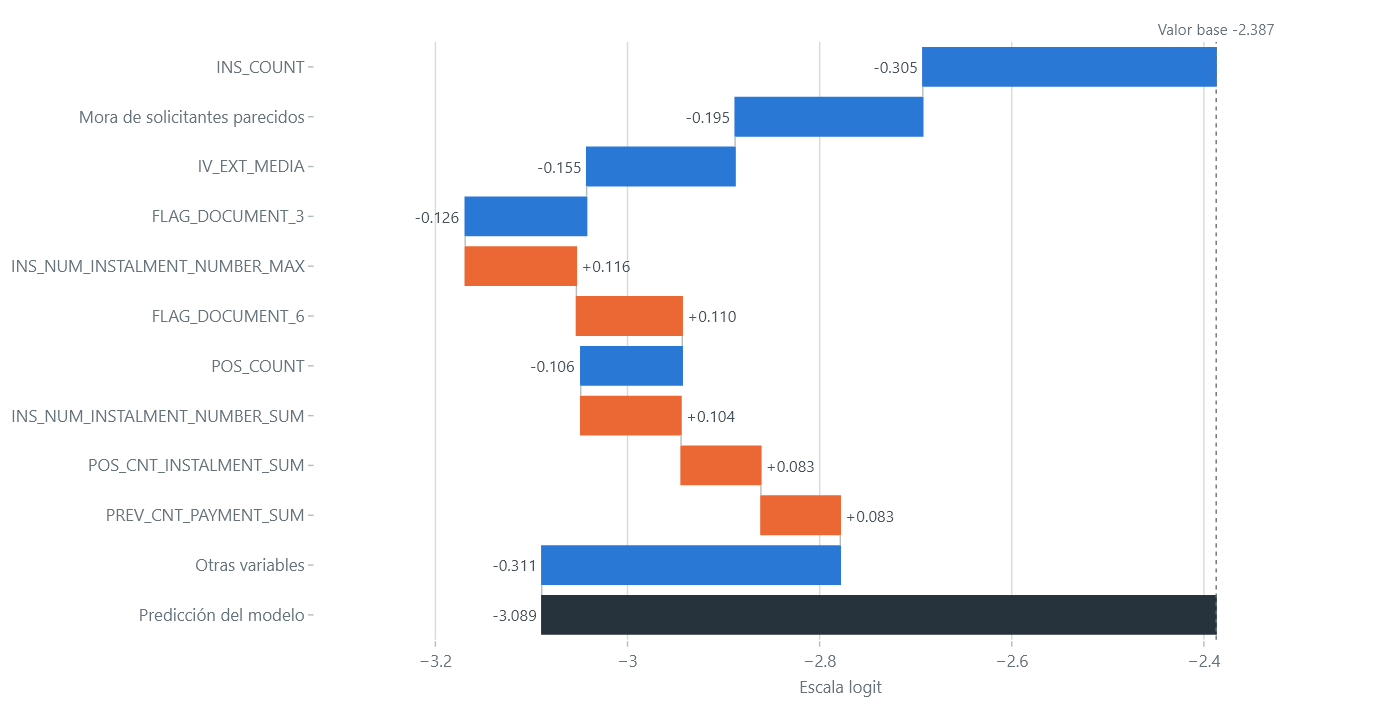

<small>Contribuciones exactas de ELAR-R en escala logit: valor base más la suma da el logit (-3.089). Se muestran las 10 mayores; las variables sensibles van dentro de «Otras variables».</small>

### Caso 20

Probabilidad calibrada (isotónica) de incumplir
56.5 %
! Sobre el umbral de coste
Etiqueta conforme:  riesgo alto . Es decir, con 90 % de confianza, el conjunto de predicción solo contiene «incumple».
En la prueba, esta persona  pagó .
Umbral de coste interno de ELAR-R: 0.0912 sobre la probabilidad sin calibrar (0.4851).


**En este caso, «Mora de solicitantes parecidos» es lo que más sube el riesgo**

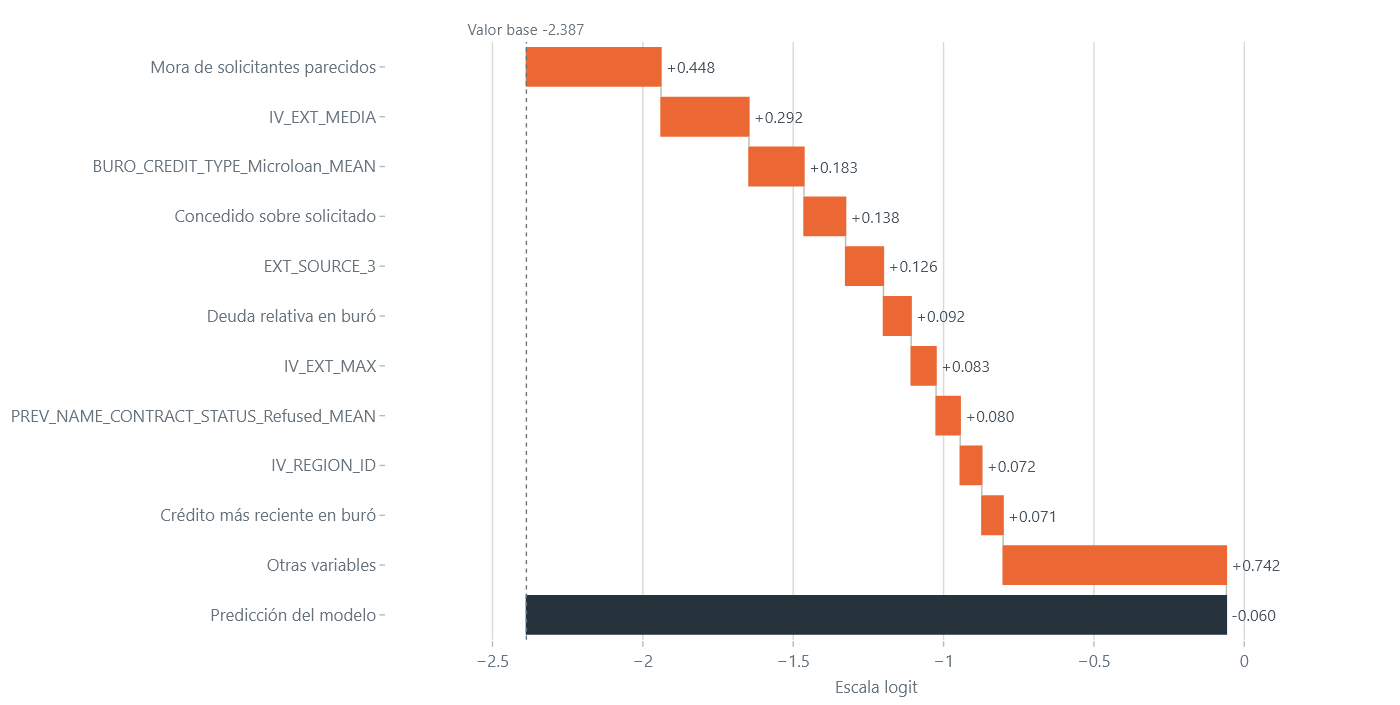

<small>Contribuciones exactas de ELAR-R en escala logit: valor base más la suma da el logit (-0.060). Se muestran las 10 mayores; las variables sensibles van dentro de «Otras variables».</small>

In [24]:
for caso in ("Caso 10", "Caso 20"):
    datos, fig, titulo, nota = modelos.mostrar_caso(caso, TEMA)
    display(Markdown(f"### {caso}"))
    print(limpio(texto(datos)))
    mostrar(fig, titulo, nota)

## 8. Prueba de la aplicación web y validación de las cifras

Se piden las tres páginas y los endpoints internos de Dash al servidor Flask de la aplicación (el mismo `server` de gunicorn):

In [25]:
cliente = aplicacion.server.test_client()
rutas = ["/", "/eda", "/modelos", "/_dash-layout", "/_dash-dependencies", "/assets/style.css"]
pd.DataFrame([{"ruta": r, "estado HTTP": (resp := cliente.get(r)).status_code, "bytes": len(resp.data)} for r in rutas]).set_index("ruta")

,estado HTTP,bytes
ruta,,
/,200,8159
/eda,200,8170
/modelos,200,8164
/_dash-layout,200,3021
/_dash-dependencies,200,6324
/assets/style.css,200,32755


In [26]:
print(f"Memoria del proceso tras cargar los modelos usados: {sv.memoria_mb():.0f} MB (límite del plan gratuito de Render: 512 MB)")
print("Modelos en la caché perezosa:", sv.cargar_modelo.cache_info())

Memoria del proceso tras cargar los modelos usados: 88 MB (límite del plan gratuito de Render: 512 MB)
Modelos en la caché perezosa: CacheInfo(hits=6, misses=12, maxsize=2, currsize=2)


`scripts/validar_dashboard.py` comprueba que las cifras del dashboard coinciden con sus fuentes (sin datos sintéticos, tablas,
calibradores, SHAP que suma al logit y predicción en vivo de cada modelo):

In [27]:
import subprocess
salida = subprocess.run([sys.executable, "scripts/validar_dashboard.py"], capture_output=True, text=True, encoding="utf-8",
                        errors="replace", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
print(salida.stdout[-6000:])
assert salida.returncode == 0 and "FALLA" not in salida.stdout

Estado: etapa B con datos reales
[OK ] resumen.json sin bandera demo  claves=['calibracion_elar', 'coste_fn', 'eda', 'entre_conjuntos', 'etapa_b', 'fecha', 'friedman_home_credit', 'fuente_entre_conjuntos', 'fuente_etapa_b', 'fuente_friedman', 'fuente_tamano', 'n_columnas_e3', 'n_columnas_elar', 'n_desarrollo', 'n_prueba', 'n_total', 'oof', 'pesos_elar', 'prevalencia', 'versiones']
[OK ] existen todos los archivos de la etapa B  
[OK ] eda_celdas suma el desarrollo real  246,008 y 19,860 en mora
[OK ] eda_categorias: cada variable suma el desarrollo  
[OK ] eda_categorias: sin variables sensibles  
[OK ] eda_hist: ninguna variable supera el desarrollo  
[OK ] curvas: AUC de cada modelo = metadata.json (7 modelos)  {}
[OK ] curvas: matrices suman la prueba y sus 4,965 moras  
[OK ] calibradores: 7, con las 246,008 etiquetas del desarrollo  
[OK ] SHAP global: 20,000 filas reales y sin variables sensibles  
[OK ] casos de ELAR-R: 20, de la prueba  
[OK ] cache OOF sin archivos _demo_  
[O

## Conclusión

El cuaderno ejecutó el código del dashboard de principio a fin: cargó la aplicación, recorrió las tres páginas llamando a sus
callbacks, dibujó cada figura, hizo predicciones en vivo con los seis modelos servidos, mostró las explicaciones locales y los
casos de ELAR-R, y comprobó que el servidor responde y que las cifras coinciden con sus fuentes. La misma aplicación está
publicada en https://dashriesgocrediticio.onrender.com.